In [15]:
import numpy as np
import pandas as pd
import baseflow

# Load your numpy arrays
forcings = np.load("/home/s0shar47/scratch/salil/CAMELS_531/PUB/1/train/f_obs_531_with_BFI.npy", allow_pickle=True)
attributes = np.load("/home/s0shar47/scratch/salil/CAMELS_531/PUB/1/train/attr_531.npy", allow_pickle=True)

# Print shapes to identify dimensions (e.g., basins x timesteps x variables)
print("Forcings shape:", forcings.shape)
print("Attributes shape:", attributes.shape)
basin_idx = 0

# Extract the vectors (Update the array slicing below to match your exact .npy layout)
# Example layout: column 0 is Precipitation (mm/day), column 4 is Streamflow (mm/day)
P = forcings[basin_idx, :, 0]  
Q = forcings[basin_idx, :, 3] 
df_streamflow = pd.DataFrame({f'Basin_{basin_idx}': Q})

# 4. Invoke the separation function using the 'methods' string parameter
# Set methods=['Furey'] to isolate the Furey-Gupta computation
df_results = baseflow.separation(df_streamflow, method=['Furey'])

# 5. Extract the numerical baseflow array
baseflow_furey = df_results['Furey'].values
quickflow = Q - baseflow_furey

print("Baseflow separation computed successfully!")

Forcings shape: (478, 12418, 5)
Attributes shape: (478, 35)


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 30.33it/s]

Baseflow separation computed successfully!


In [8]:
basin_idx = 0

# Extract the vectors (Update the array slicing below to match your exact .npy layout)
# Example layout: column 0 is Precipitation (mm/day), column 4 is Streamflow (mm/day)
P = forcings[basin_idx, :, 0]  
Q = forcings[basin_idx, :, 3]  

# Replace negative values (common filler code for missing streamflow data in CAMELS)
# Q[Q < 0] = 0

In [ ]:
# Example: Extracting static attributes if needed for calibration or multi-basin loops
# static_area = attributes[basin_idx, 2] # Example index for basin drainage area

# Standard calibrated baseline values for the Furey filter
gamma_val = 0.05   # Recession constant
c1_val = 0.20      # Quick overland flow fraction
c3_val = 0.30      # Groundwater recharge fraction
lag_d = 2          # Time lag delay (days)

In [11]:
df_streamflow = pd.DataFrame({f'Basin_{basin_idx}': Q})

# 4. Invoke the separation function using the 'methods' string parameter
# Set methods=['Furey'] to isolate the Furey-Gupta computation
df_results = baseflow.separation(df_streamflow, method=['Furey'])

# 5. Extract the numerical baseflow array
baseflow_furey = df_results['Furey'].values
quickflow = Q - baseflow_furey

print("Baseflow separation computed successfully!")

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:04<00:00,  4.13s/it]

Baseflow separation computed successfully!


In [14]:
baseflow_furey

array([[58.        ],
       [55.89114577],
       [53.95174772],
       ...,
       [83.48862931],
       [80.60750282],
       [77.86989801]], shape=(12418, 1))

In [12]:
import numpy as np
import pandas as pd
import baseflow
import json

actions=['test','train']

for i in range(1,11):
    for action in actions:
    
# 1. Load your raw numpy arrays from your scratch path
        forcings_path = f"/home/s0shar47/scratch/Daymet_Folds/{i}/{action}/daymet_19800101_20141231_forcing_671.npy"

        file_path = f"/home/s0shar47/scratch/Daymet_Folds/{i}/{action}/daymet_19800101_20141231_forcing_671_name.json"
        with open(file_path, "r") as f:
            data = json.load(f)

        # # append new entry
        data.append("baseflow")
        forcings = np.load(forcings_path, allow_pickle=True)

        attr= np.load(f"/home/s0shar47/scratch/Daymet_Folds/{i}/{action}/daymet_19800101_20141231_attr_671.npy", allow_pickle=True)
        np.save(f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/{action}/daymet_19800101_20141231_attr_671.npy", attr)

        print("Original Forcings shape:", forcings.shape) 
        # Expecting (num_basins, num_timesteps, num_variables)

        num_basins = forcings.shape[0]
        num_timesteps = forcings.shape[1]

        # 2. Pre-allocate an empty array to temporarily hold the baseflow timeseries for all basins
        all_baseflows = np.zeros((num_basins, num_timesteps))

        # 3. Loop through every basin to compute the Furey-Gupta separation vector
        # We do this because baseflow.separation expects data arranged by basin column matrices
        for basin_idx in range(num_basins):
            # Extract streamflow vector for current basin (index 3 based on your configuration)
            Q = forcings[basin_idx, :, 12].copy()
            
            # Clean anomalies or missing data flags (e.g., -99.0) safely to float zeros
            Q = np.where(Q < 0, 0.0, Q).astype(float)
            
            # Create the single-column DataFrame format expected by the package wrapper
            df_streamflow = pd.DataFrame({f'Basin_{basin_idx}': Q})
            
            try:
                # Note: the parameter name in the API signature is 'methods' (plural list)
                df_results = baseflow.separation(df_streamflow, methods=['Furey'])
                baseflow_vector = df_results['Furey'].values
            except Exception as e:
                # Fallback safeguard: If a specific basin fails or has math bounds errors, 
                # initialize it with a basic default or local minimum approach
                baseflow_vector = np.zeros(num_timesteps)
                
            all_baseflows[basin_idx, :] = baseflow_vector

        # 4. Reshape all_baseflows from (basins, timesteps) to (basins, timesteps, 1) 
        # This matches the final dimensional slice requirements for an axis-2 concat
        all_baseflows_reshaped = np.expand_dims(all_baseflows, axis=2)

        # 5. Append the calculated baseflow as the NEW LAST COLUMN inside the forcings array
        updated_forcings = np.concatenate((forcings, all_baseflows_reshaped), axis=2)

        print("New Forcings shape with Furey Baseflow added:", updated_forcings.shape)
        # The final dimension count will increase by +1 (e.g., from 5 to 6)

        # 6. Save the array right back over the original file (or create a new explicit variant file)
        output_path = f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/{action}/DAYMET_19800101_20141231_forcing_baseflow.npy"
        np.save(output_path, updated_forcings)

        with open(f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/{action}/DAYMET_19800101_20141231_forcing_baseflow_name.json", "w") as f:
            json.dump(data, f)

        print(f"Updated metadata saved to: /home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/{action}/DAYMET_19800101_20141231_forcing_baseflow_name.json")

        print(f"Success! Array saved securely to: {output_path}")

Original Forcings shape: (52, 12784, 15)
New Forcings shape with Furey Baseflow added: (52, 12784, 16)
Updated metadata saved to: /home/s0shar47/scratch/BASEFLOW_FOLDS/1/test/DAYMET_19800101_20141231_forcing_baseflow_name.json
Success! Array saved securely to: /home/s0shar47/scratch/BASEFLOW_FOLDS/1/test/DAYMET_19800101_20141231_forcing_baseflow.npy
Original Forcings shape: (604, 12784, 15)
New Forcings shape with Furey Baseflow added: (604, 12784, 16)
Updated metadata saved to: /home/s0shar47/scratch/BASEFLOW_FOLDS/1/train/DAYMET_19800101_20141231_forcing_baseflow_name.json
Success! Array saved securely to: /home/s0shar47/scratch/BASEFLOW_FOLDS/1/train/DAYMET_19800101_20141231_forcing_baseflow.npy
Original Forcings shape: (54, 12784, 15)
New Forcings shape with Furey Baseflow added: (54, 12784, 16)
Updated metadata saved to: /home/s0shar47/scratch/BASEFLOW_FOLDS/2/test/DAYMET_19800101_20141231_forcing_baseflow_name.json
Success! Array saved securely to: /home/s0shar47/scratch/BASEFLOW

In [7]:
import os
actions=['test','train']
for action in actions:
    for i in range(1,11):
        os.mkdir(f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/{action}")

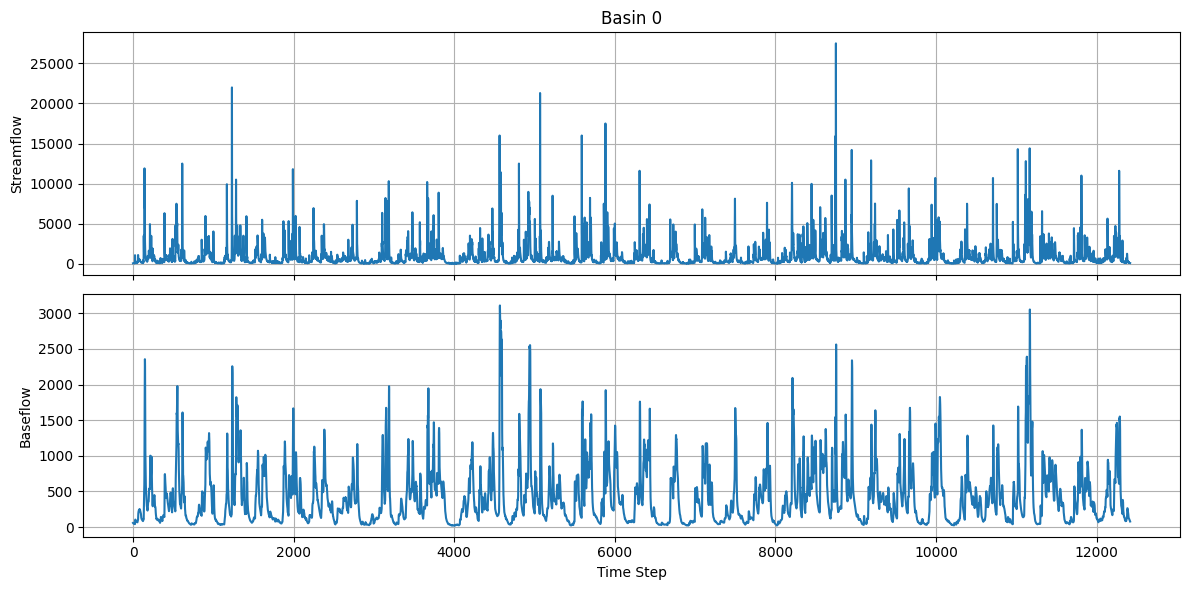

In [40]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

# Streamflow
ax[0].plot(forcings[0, :, 3])
ax[0].set_ylabel("Streamflow")
ax[0].set_title("Basin 0")
ax[0].grid(True)

# Baseflow
ax[1].plot(df_results['Furey'].values)
ax[1].set_ylabel("Baseflow")
ax[1].set_xlabel("Time Step")
ax[1].grid(True)

plt.tight_layout()
plt.show()

In [21]:
import numpy as np
names=["Year", "Mnth", "Day", "Hr", "dayl(s)", "prcp(mm/day)", 
       "srad(W/m2)", "swe(mm)", "tmax(C)", "tmin(C)", "vp(Pa)", 
       "PEVAP", "00060_Mean", "tmean(C)", "gage_id", "baseflow"]

bs= np.load("/home/s0shar47/scratch/BASEFLOW_FOLDS/1/test/DAYMET_19800101_20141231_forcing_baseflow.npy")

for i in range(bs.shape[0]):
    print(f"GaugeID: {bs[i,1,14]}")
    print(f"Streamflow: {bs[i,:,12], bs[i,:,12].shape}")
    print(f"Baseflow: {bs[i,:,15], bs[i,:,15].shape}")


GaugeID: 1137500.0
Streamflow: (array([  74.,   70.,   66., ..., -999., -999., -999.], shape=(12784,)), (12784,))
Baseflow: (array([0., 0., 0., ..., 0., 0., 0.], shape=(12784,)), (12784,))
GaugeID: 1181000.0
Streamflow: (array([ 164.,  155.,  140., ..., -999., -999., -999.], shape=(12784,)), (12784,))
Baseflow: (array([0., 0., 0., ..., 0., 0., 0.], shape=(12784,)), (12784,))
GaugeID: 1350000.0
Streamflow: (array([ 220.,  210.,  190., ..., -999., -999., -999.], shape=(12784,)), (12784,))
Baseflow: (array([0., 0., 0., ..., 0., 0., 0.], shape=(12784,)), (12784,))
GaugeID: 1414500.0
Streamflow: (array([  36.,   34.,   31., ..., -999., -999., -999.], shape=(12784,)), (12784,))
Baseflow: (array([0., 0., 0., ..., 0., 0., 0.], shape=(12784,)), (12784,))
GaugeID: 1439500.0
Streamflow: (array([201., 194., 187., ..., 250., 222., 201.], shape=(12784,)), (12784,))
Baseflow: (array([0., 0., 0., ..., 0., 0., 0.], shape=(12784,)), (12784,))
GaugeID: 1451800.0
Streamflow: (array([  90.,   81.,   74., .

In [ ]:
import matplotlib.pyplot as plt

for i in range(bs.shape[0]):
    plt.figure(figsize=(12, 4))
    plt.plot(bs[1, :, 15])
    plt.xlabel("Time Step")
    plt.ylabel("Value")
    plt.title("Time Series: Basin 1, Feature 15")
    plt.grid(True)
    plt.show()

In [ ]:
import numpy as np
import baseflow
import matplotlib.pyplot as plt
import pandas as pd

forcings= np.load("/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671.npy")

q = forcings[28, :, 12].copy()
q[q == (-999)] = np.nan
q[q <(0)] = 0
df_streamflow = pd.DataFrame({f'Basin_1': q})
df_streamflow

    # Note: the parameter name in the API signature is 'methods' (plural list)
# baseflow_vector = df_results['Furey'].values

df_results = baseflow.separation(df_streamflow, method=['Furey'])

baseflow_furey = df_results['Furey'].values

baseflow_furey


100%|██████████| 1/1 [00:00<00:00, 38.61it/s]


12784

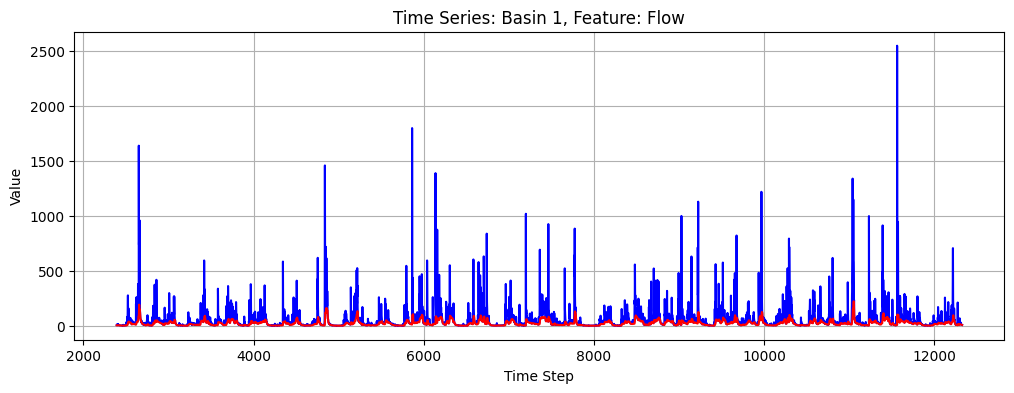

In [22]:
plt.figure(figsize=(12, 4))
plt.plot(q, color='blue')
plt.plot(baseflow_furey, color='red')
plt.xlabel("Time Step")
plt.ylabel("Value")
plt.title("Time Series: Basin 1, Feature: Flow")
plt.grid(True)
plt.show()

In [13]:
import numpy as np
import pandas as pd
import baseflow
import json

actions=['test','train']

for i in range(1,11):
    for action in actions:
    
# 1. Load your raw numpy arrays from your scratch path
        forcings_path = f"/home/s0shar47/scratch/Daymet_Folds/{i}/{action}/daymet_19800101_20141231_forcing_671.npy"

        file_path = f"/home/s0shar47/scratch/Daymet_Folds/{i}/{action}/daymet_19800101_20141231_forcing_671_name.json"
        with open(file_path, "r") as f:
            data = json.load(f)

        # # append new entry
        data.append("baseflow")
        forcings = np.load(forcings_path, allow_pickle=True)

        attr= np.load(f"/home/s0shar47/scratch/Daymet_Folds/{i}/{action}/daymet_19800101_20141231_attr_671.npy", allow_pickle=True)
        np.save(f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/{action}/daymet_19800101_20141231_attr_671.npy", attr)

        print("Original Forcings shape:", forcings.shape) 
        # Expecting (num_basins, num_timesteps, num_variables)

        num_basins = forcings.shape[0]
        num_timesteps = forcings.shape[1]

        # 2. Pre-allocate an empty array to temporarily hold the baseflow timeseries for all basins
        all_baseflows = np.zeros((num_basins, num_timesteps))

        # 3. Loop through every basin to compute the Furey-Gupta separation vector
        # We do this because baseflow.separation expects data arranged by basin column matrices
        for basin_idx in range(num_basins):
            # Extract streamflow vector for current basin (index 3 based on your configuration)
            Q = forcings[basin_idx, :, 12].copy().astype(float)
            
            # Clean anomalies or missing data flags (e.g., -99.0) safely to float zeros
            # Q = np.where(Q < 0, 0.0, Q).astype(float)
            Q[Q==(-999.0)] = np.nan
            Q[Q<0] = 0
            
            # Create the single-column DataFrame format expected by the package wrapper
            df_streamflow = pd.DataFrame({f'Basin_{basin_idx}': Q})
            
            
            # Note: the parameter name in the API signature is 'methods' (plural list)
            df_results = baseflow.separation(df_streamflow, method=['Furey'])
            baseflow_vector = df_results['Furey'].values

            baseflow_vector = baseflow_vector.squeeze()
            
                
            all_baseflows[basin_idx, :] = baseflow_vector

        # 4. Reshape all_baseflows from (basins, timesteps) to (basins, timesteps, 1) 
        # This matches the final dimensional slice requirements for an axis-2 concat
        all_baseflows_reshaped = np.expand_dims(all_baseflows, axis=2)

        # 5. Append the calculated baseflow as the NEW LAST COLUMN inside the forcings array
        updated_forcings = np.concatenate((forcings, all_baseflows_reshaped), axis=2)

        print("New Forcings shape with Furey Baseflow added:", updated_forcings.shape)
        # # The final dimension count will increase by +1 (e.g., from 5 to 6)

        # 6. Save the array right back over the original file (or create a new explicit variant file)
        output_path = f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/{action}/DAYMET_19800101_20141231_forcing_baseflow.npy"
        np.save(output_path, updated_forcings)

        # # with open(f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/{action}/DAYMET_19800101_20141231_forcing_baseflow_name.json", "w") as f:
        # #     json.dump(data, f)

        # # print(f"Updated metadata saved to: /home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/{action}/DAYMET_19800101_20141231_forcing_baseflow_name.json")

        print(f"Success! Array saved securely to: {output_path}")

Original Forcings shape: (52, 12784, 15)


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 33.04it/s]


New Forcings shape with Furey Baseflow added: (52, 12784, 16)
Success! Array saved securely to: /home/s0shar47/scratch/BASEFLOW_FOLDS/1/test/DAYMET_19800101_20141231_forcing_baseflow.npy
Original Forcings shape: (604, 12784, 15)


100%|██████████| 1/1 [00:00<00:00, 27.71it/s]


...

New Forcings shape with Furey Baseflow added: (604, 12784, 16)
Success! Array saved securely to: /home/s0shar47/scratch/BASEFLOW_FOLDS/9/train/DAYMET_19800101_20141231_forcing_baseflow.npy
Original Forcings shape: (56, 12784, 15)


100%|██████████| 1/1 [00:00<00:00, 33.07it/s]


New Forcings shape with Furey Baseflow added: (56, 12784, 16)
Success! Array saved securely to: /home/s0shar47/scratch/BASEFLOW_FOLDS/10/test/DAYMET_19800101_20141231_forcing_baseflow.npy
Original Forcings shape: (603, 12784, 15)


100%|██████████| 1/1 [00:00<00:00, 31.16it/s]


New Forcings shape with Furey Baseflow added: (603, 12784, 16)
Success! Array saved securely to: /home/s0shar47/scratch/BASEFLOW_FOLDS/10/train/DAYMET_19800101_20141231_forcing_baseflow.npy


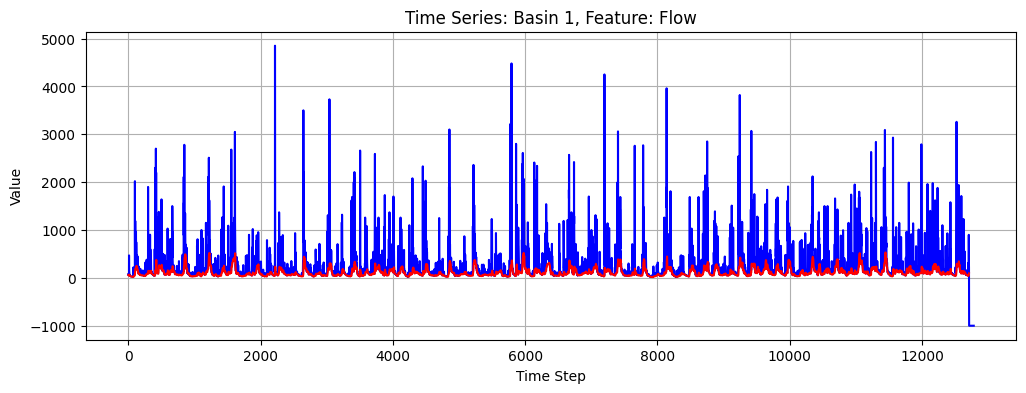

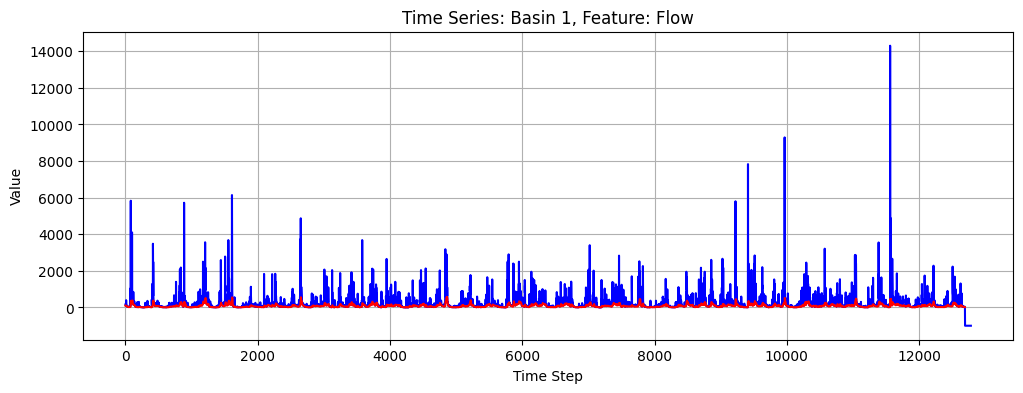

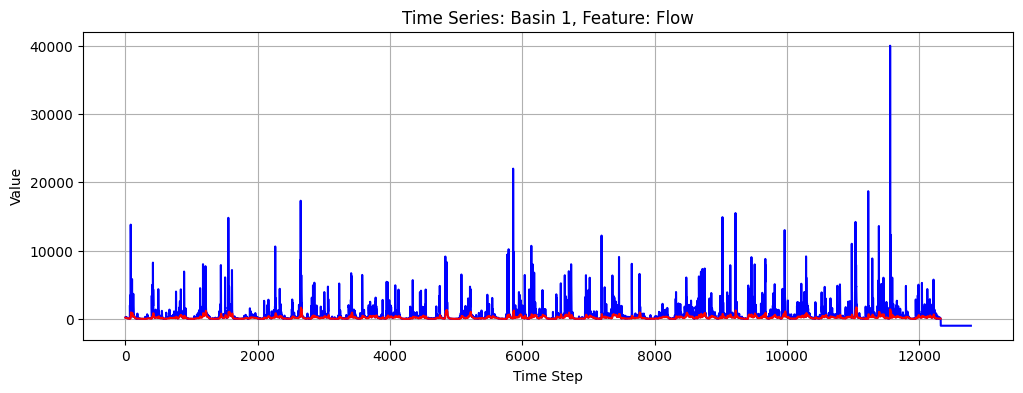

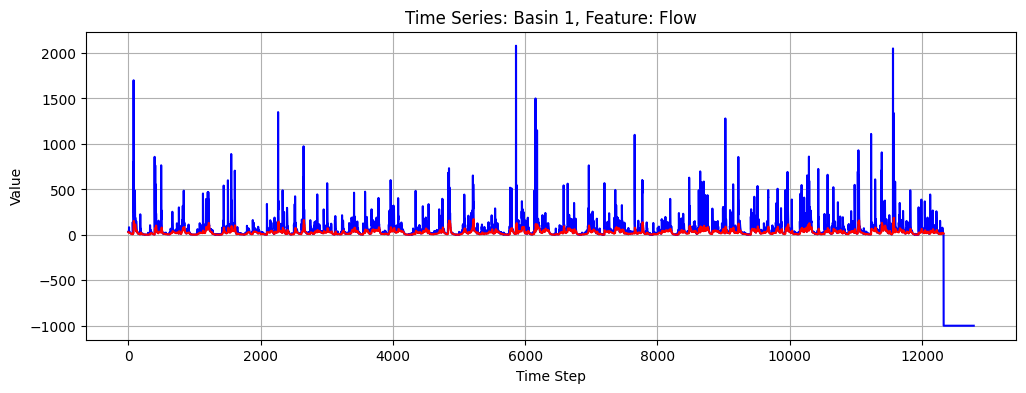

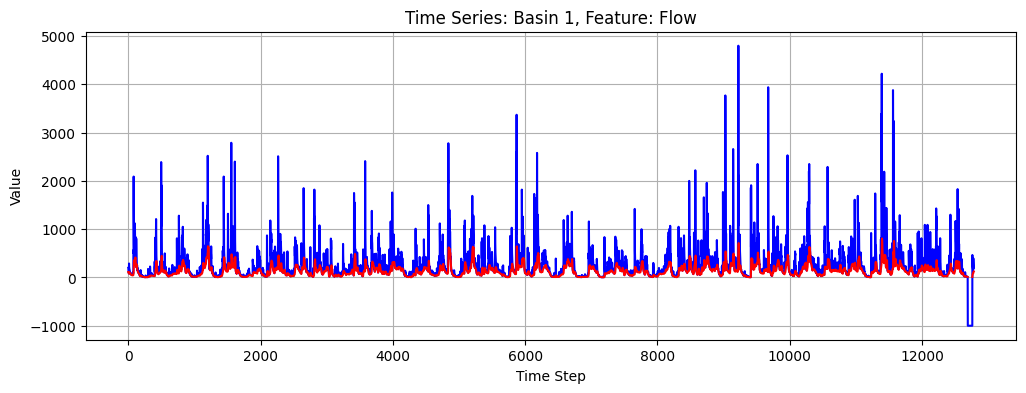

In [ ]:
import matplotlib.pyplot as plt
for i in range(5):
    plt.figure(figsize=(12, 4))
    plt.plot(updated_forcings[i,:,12], color='blue')
    plt.plot(updated_forcings[i,:,15], color='red')
    plt.xlabel("Time Step")
    plt.ylabel("Value")
    plt.title("Time Series: Basin 1, Feature: Flow")
    plt.grid(True)
    plt.show()

In [7]:
import numpy as np
import pandas as pd
import baseflow
import json

method= 'hysep_interval'

actions=['test','train']

for i in range(0,1):
    
# 1. Load your raw numpy arrays from your scratch path
        forcings_path = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671.npy"

        file_path = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_name.json"
        with open(file_path, "r") as f:
            data = json.load(f)

        # # append new entry
        data.append("baseflow")
        forcings = np.load(forcings_path, allow_pickle=True)

        attr= np.load(f"/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_attr_671.npy", allow_pickle=True)
        # np.save(f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/{action}/daymet_19800101_20141231_attr_671.npy", attr)

        print("Original Forcings shape:", forcings.shape) 
        # Expecting (num_basins, num_timesteps, num_variables)

        num_basins = forcings.shape[0]
        num_timesteps = forcings.shape[1]

        # 2. Pre-allocate an empty array to temporarily hold the baseflow timeseries for all basins
        all_baseflows = np.zeros((num_basins, num_timesteps))

        # 3. Loop through every basin to compute the Furey-Gupta separation vector
        # We do this because baseflow.separation expects data arranged by basin column matrices
        for basin_idx in range(num_basins):
            # Extract streamflow vector for current basin (index 3 based on your configuration)
            Q = forcings[basin_idx, :, 12].copy().astype(float)
            
            # Clean anomalies or missing data flags (e.g., -99.0) safely to float zeros
            # Q = np.where(Q < 0, 0.0, Q).astype(float)
            Q[Q==(-999.0)] = np.nan
            Q[Q<0] = 0
            
            # Create the single-column DataFrame format expected by the package wrapper
            df_streamflow = pd.DataFrame({f'Basin_{basin_idx}': Q})
            
            
            # Note: the parameter name in the API signature is 'methods' (plural list)
            df_results = baseflow.separation(df_streamflow, method=[method])
            baseflow_vector = df_results[method].values

            baseflow_vector = baseflow_vector.squeeze()
            
                
            all_baseflows[basin_idx, :] = baseflow_vector

        # 4. Reshape all_baseflows from (basins, timesteps) to (basins, timesteps, 1) 
        # This matches the final dimensional slice requirements for an axis-2 concat
        all_baseflows_reshaped = np.expand_dims(all_baseflows, axis=2)

        # 5. Append the calculated baseflow as the NEW LAST COLUMN inside the forcings array
        updated_forcings = np.concatenate((forcings, all_baseflows_reshaped), axis=2)

        print(f"New Forcings shape with {method} Baseflow added:", updated_forcings.shape)


        area_km2 = attr[:, 11]
        area_m2 = area_km2 * 1e6

        # -----------------------------
        # Convert baseflow:
        # ft³/s -> m³/day -> m/day
        # -----------------------------
        FT3S_TO_M3DAY = 0.0283168 * 86400  # 2446.57152

        # Convert ft³/s to m³/day
        updated_forcings[:, :, -1] *= FT3S_TO_M3DAY

        # Convert m³/day to m/day by dividing by basin area
        updated_forcings[:, :, -1] /= area_m2[:, np.newaxis]

        # m/day -> mm/day
        updated_forcings[:, :, -1] *= 1000.0

        # # The final dimension count will increase by +1 (e.g., from 15 to 16)
        print("Baseflow converted to mm/day, Shape:", updated_forcings.shape)

        # # 6. Save the array right back over the original file (or create a new explicit variant file)
        # output_path = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_eckhardt_mmday.npy"
        # np.save(output_path, updated_forcings)
        
        # with open(f"/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_eckhardt_mmday_name.json", "w") as f:
        #     json.dump(data, f)

        # print(f"/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_eckhardt_name_mmday.json")

        # print(f"Success! Array saved securely to: {output_path}")

Original Forcings shape: (671, 12784, 15)


100%|██████████| 1/1 [00:00<00:00, 739.21it/s]


New Forcings shape with hysep_interval Baseflow added: (671, 12784, 16)
Baseflow converted to mm/day, Shape: (671, 12784, 16)


In [2]:
import baseflow 
baseflow.__dict__

{'__name__': 'baseflow',
 '__doc__': None,
 '__package__': 'baseflow',
 '__loader__': <_frozen_importlib_external.SourceFileLoader at 0x7af1e131dc90>,
 '__spec__': ModuleSpec(name='baseflow', loader=<_frozen_importlib_external.SourceFileLoader object at 0x7af1e131dc90>, origin='/home/s0shar47/.local/lib/python3.10/site-packages/baseflow/__init__.py', submodule_search_locations=['/home/s0shar47/.local/lib/python3.10/site-packages/baseflow']),
 '__path__': ['/home/s0shar47/.local/lib/python3.10/site-packages/baseflow'],
 '__file__': '/home/s0shar47/.local/lib/python3.10/site-packages/baseflow/__init__.py',
 '__cached__': '/home/s0shar47/.local/lib/python3.10/site-packages/baseflow/__pycache__/__init__.cpython-310.pyc',
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, exceptions, and other objects.\n\nNoteworthy: None is the `nil' object; Ellipsis represents `...' in slices.",
  '__package__': '',
  '__loader__': _frozen_importlib.BuiltinImporter,
  '__spec__': 

In [ ]:
import numpy as np
import pandas as pd
import baseflow
import json

method = 'hysep_interval'
actions = ['test', 'train']

for i in range(0, 1):
    # 1. Load your raw numpy arrays from your scratch path
    forcings_path = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671.npy"

    file_path = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_name.json"
    with open(file_path, "r") as f:
        data = json.load(f)

    # Append new entry
    data.append("baseflow")
    forcings = np.load(forcings_path, allow_pickle=True)

    attr = np.load(f"/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_attr_671.npy", allow_pickle=True)

    print("Original Forcings shape:", forcings.shape) 
    # Expecting (num_basins, num_timesteps, num_variables)

    num_basins = forcings.shape[0]
    num_timesteps = forcings.shape[1]

    # Extract basin areas (index 11) in km^2
    area_km2 = attr[:, 11]

    # 2. Pre-allocate an empty array to temporarily hold the baseflow timeseries for all basins
    all_baseflows = np.zeros((num_basins, num_timesteps))

    # 3. Loop through every basin to compute the separation vector using drainage area
    for basin_idx in range(num_basins):
        # Extract streamflow vector for current basin (index 12)
        Q = forcings[basin_idx, :, 12].copy().astype(float)
        
        # Clean anomalies or missing data flags safely
        Q[Q == (-999.0)] = np.nan
        Q[Q < 0] = 0
        
        # Create the single-column DataFrame format expected by the package wrapper
        df_streamflow = pd.DataFrame({f'Basin_{basin_idx}': Q})
        
        # Create a stations DataFrame with the drainage area for the current basin
        # baseflow.separation expects 'area' to calculate HYSEP intervals ($2N^*$ days)
        df_stations = pd.DataFrame({
            'lon': [attr[:, 11][basin_idx]],  # Placeholder if longitude isn't strictly required by the filter
            'lat': [attr[:, 11][basin_idx]],  # Placeholder if latitude isn't strictly required by the filter
            'area': [area_km2[basin_idx]]
        }, index=[f'Basin_{basin_idx}'])
        
        # Pass stations data containing the area into the separation function
        df_results = baseflow.separation(df_streamflow, df_stations, method=[method])
        baseflow_vector = df_results[method].values

        baseflow_vector = baseflow_vector.squeeze()
            
        all_baseflows[basin_idx, :] = baseflow_vector

    # 4. Reshape all_baseflows from (basins, timesteps) to (basins, timesteps, 1) 
    all_baseflows_reshaped = np.expand_dims(all_baseflows, axis=2)

    # 5. Append the calculated baseflow as the NEW LAST COLUMN inside the forcings array
    updated_forcings = np.concatenate((forcings, all_baseflows_reshaped), axis=2)

    print(f"New Forcings shape with {method} Baseflow added:", updated_forcings.shape)

    area_m2 = area_km2 * 1e6

    # -----------------------------
    # Convert baseflow:
    # ft³/s -> m³/day -> m/day -> mm/day
    # -----------------------------
    FT3S_TO_M3DAY = 0.0283168 * 86400  # 2446.57152

    # Convert ft³/s to m³/day
    updated_forcings[:, :, -1] *= FT3S_TO_M3DAY

    # Convert m³/day to m/day by dividing by basin area
    updated_forcings[:, :, -1] /= area_m2[:, np.newaxis]

    # m/day -> mm/day
    updated_forcings[:, :, -1] *= 1000.0

    print("Baseflow converted to mm/day, Shape:", updated_forcings.shape)
    # # 6. Save the array right back over the original file (or create a new explicit variant file)
    output_path = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_hysep_mmday.npy"
    np.save(output_path, updated_forcings)

Original Forcings shape: (671, 12784, 15)


100%|██████████| 1/1 [00:00<00:00, 420.27it/s]


100%|██████████| 1/1 [00:00<00:00, 453.93it/s]


New Forcings shape with hysep_interval Baseflow added: (671, 12784, 16)
Baseflow converted to mm/day, Shape: (671, 12784, 16)


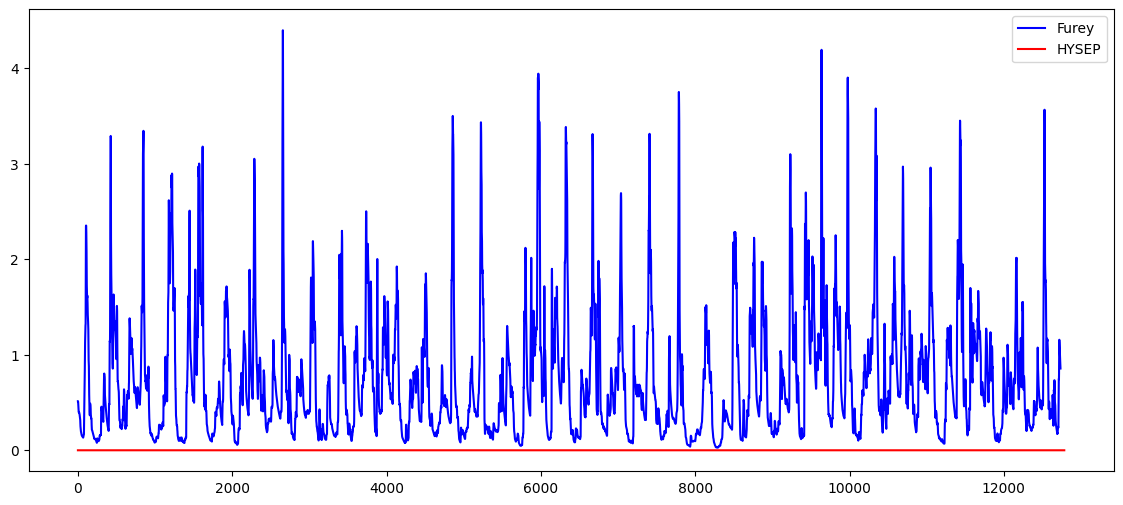

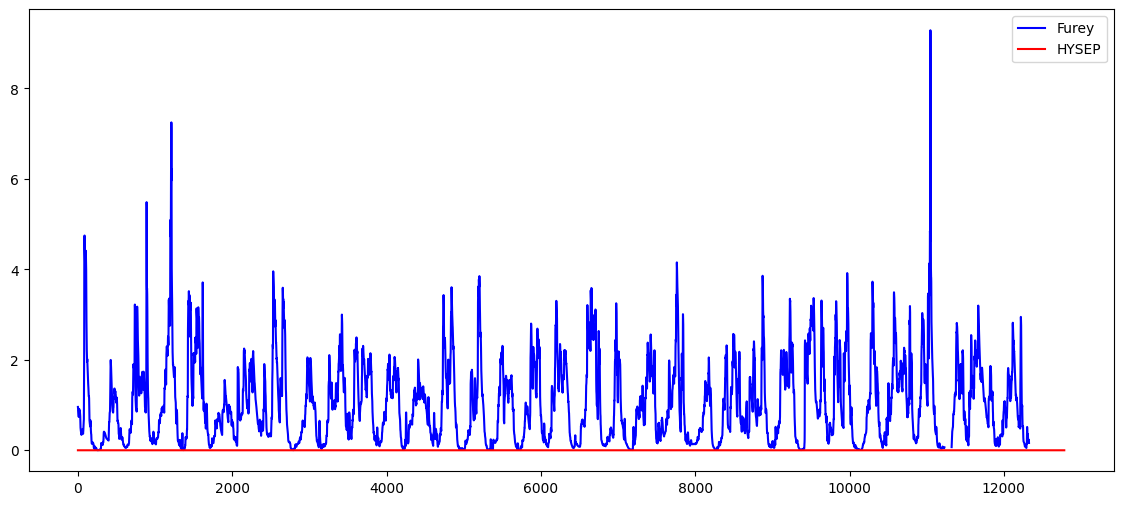

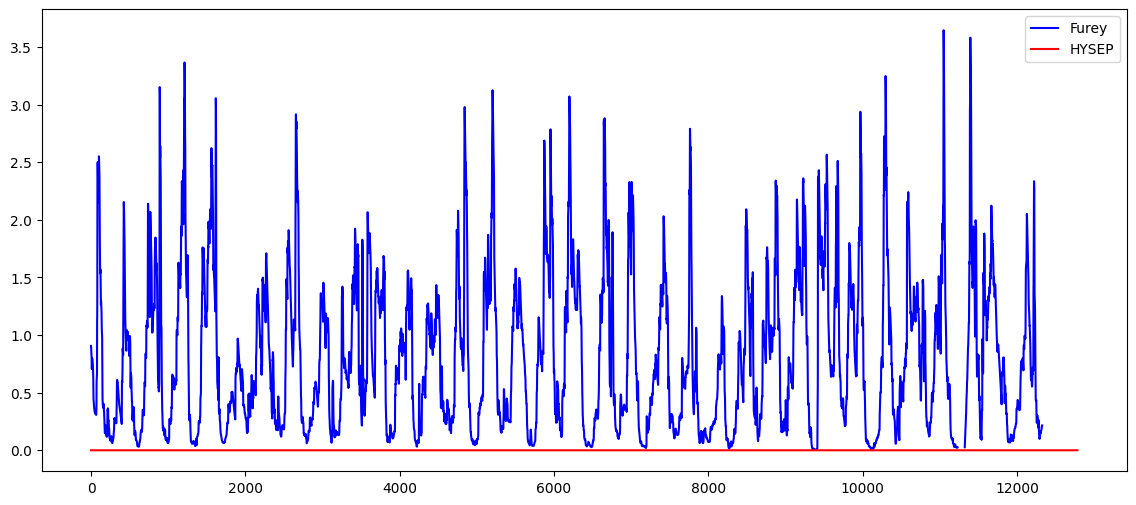

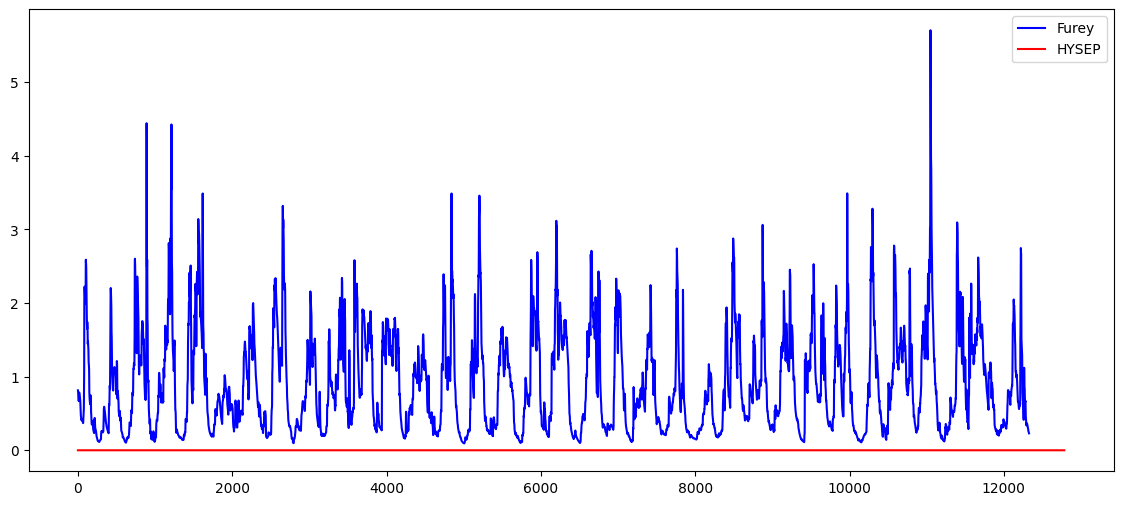

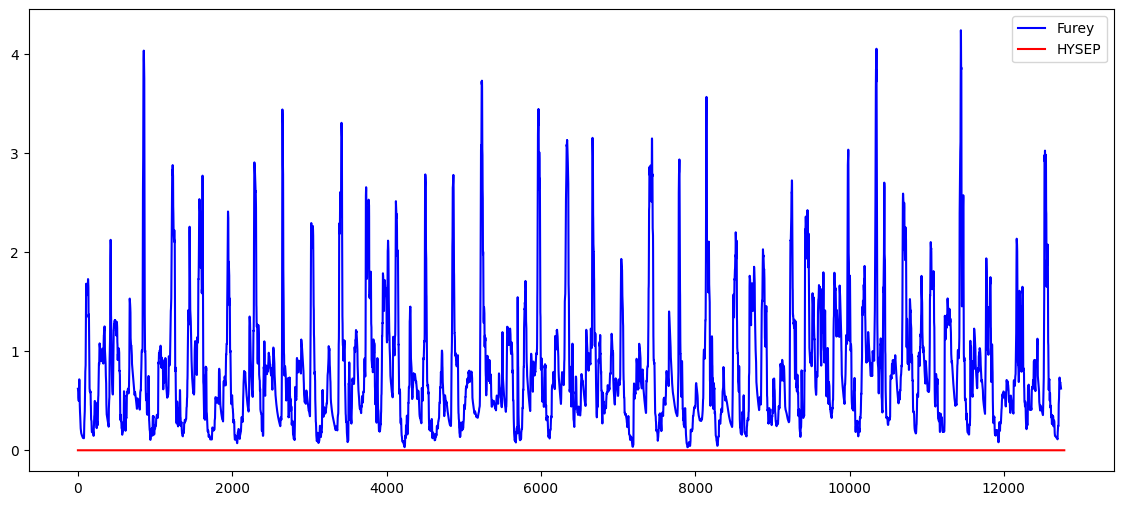

In [2]:
import numpy as np
import matplotlib.pyplot as plt

furey= np.load("/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy")
eckhardt= np.load("/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_eckhardt_mmday.npy")
usgs= np.load("/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_usgs.npy")
hysep= np.load("/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_hysep_mmday.npy")

for i in range(5):
    plt.figure(figsize=(14,6))

    plt.plot(furey[i+10,:,-1],label='Furey', color='blue')
    # plt.scatter(range(12784),eckhardt[i,:,12], label='Eckhardt',color='red')
    # plt.scatter(range(12784),usgs[i,:,12], label='USGS',color='red')
    plt.plot(range(12784),updated_forcings[i+10,:,-1], label='HYSEP',color='red')

    plt.legend()
    plt.show()



In [53]:
import pandas as pd

coord= pd.read_csv("/scratch/data/CAMELS_FORCING/basin_dataset_public_v1p2/basin_metadata/gauge_information.txt", sep='\t')
coord.rename(columns={'HUC_02  GAGE_ID':'HUC','Unnamed: 1':'GAUGE_ID','Unnamed: 2':'GAUGE_NAME','GAGE_NAME':'lat','Unnamed: 4':'lon','Unnamed: 5':'AREA'},inplace=True)
coord.drop(columns={'Unnamed: 6',
       'Unnamed: 7', 'LAT', 'Unnamed: 9', 'LONG', 'Unnamed: 11',
       'DRAINAGE AREA (KM^2)'},inplace=True)
coord

,HUC,GAUGE_ID,GAUGE_NAME,lat,lon,AREA
0,1,1013500,"Fish River near Fort Kent, M...",47.23739,-68.58264,2252.70
1,1,1022500,"Narraguagus River at Cherryfield, M...",44.60797,-67.93524,573.60
2,1,1030500,"Mattawamkeag River near Mattawamkeag, M...",45.50097,-68.30596,3676.17
3,1,1031500,"Piscataquis River near Dover-Foxcroft, M...",45.17501,-69.31470,769.05
4,1,1047000,"Carrabassett River near North Anson, M...",44.86920,-69.95510,909.10
...,...,...,...,...,...,...
666,17,14309500,WEST FORK COW CREEK NEAR GLENDALE...,42.80400,-123.61091,224.92
667,17,14316700,STEAMBOAT CREEK NEAR GLIDE...,43.34984,-122.72894,587.90
668,17,14325000,SOUTH FORK COQUILLE RIVER AT POWERS...,42.89150,-124.07065,443.07
669,17,14362250,"STAR GULCH NEAR RUCH,...",42.15401,-123.07532,41.42


In [54]:
import numpy as np
import pandas as pd
import baseflow
import json

method = 'hysep_interval'

for i in range(0, 1):
    # 1. Load your raw numpy arrays from your scratch path
    forcings_path = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671.npy"

    file_path = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_name.json"
    with open(file_path, "r") as f:
        data = json.load(f)

    # Append new entry
    data.append("baseflow")
    forcings = np.load(forcings_path, allow_pickle=True)

    attr = np.load(f"/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_attr_671.npy", allow_pickle=True)

    # 2. Load gauge information for exact lat, lon, and area
    coord = pd.read_csv("/scratch/data/CAMELS_FORCING/basin_dataset_public_v1p2/basin_metadata/gauge_information.txt", sep='\t')
    coord.rename(columns={'HUC_02  GAGE_ID':'HUC','Unnamed: 1':'GAUGE_ID','Unnamed: 2':'GAUGE_NAME','GAGE_NAME':'lat','Unnamed: 4':'lon','Unnamed: 5':'AREA'},inplace=True)
    coord.drop(columns={'Unnamed: 6',
           'Unnamed: 7', 'LAT', 'Unnamed: 9', 'LONG', 'Unnamed: 11',
           'DRAINAGE AREA (KM^2)'},inplace=True)
    
    # Convert GAUGE_ID in coord to integer to match forcings
    coord['GAUGE_ID'] = coord['GAUGE_ID'].astype(int)

    print("Original Forcings shape:", forcings.shape) 
    # Expecting (num_basins, num_timesteps, num_variables)

    num_basins = forcings.shape[0]
    num_timesteps = forcings.shape[1]

    # Extract basin areas from attributes (index 11) in km^2
    area_km2 = attr[:, 11]

    # 3. Pre-allocate an empty array to temporarily hold the baseflow timeseries for all basins
    all_baseflows = np.zeros((num_basins, num_timesteps))

    # 4. Loop through every basin to compute the separation vector by matching gauge IDs as integers
    for basin_idx in range(num_basins):
        # Extract gauge ID from forcings[:, 0, -2] and convert to integer
        gauge_id = int(float(forcings[basin_idx, 0, -2]))

        # Match gauge ID with the coord dataframe
        matched_row = coord[coord['GAUGE_ID'] == gauge_id]
        if matched_row.empty:
            raise ValueError(f"Gauge ID {gauge_id} not found in coordinate metadata file.")
        
        lat_val = float(matched_row['lat'].values[0])
        lon_val = float(matched_row['lon'].values[0])

        # Extract streamflow vector for current basin (index 12)
        Q = forcings[basin_idx, :, 12].copy().astype(float)
        
        # Clean anomalies or missing data flags safely
        Q[Q == (-999.0)] = np.nan
        Q[Q < 0] = 0
        
        # Create the single-column DataFrame format expected by the package wrapper
        df_streamflow = pd.DataFrame({f'Basin_{basin_idx}': Q})
        
        # Create a stations DataFrame with the matched lat, lon, and drainage area
        df_stations = pd.DataFrame({
            'lon': [lon_val],
            'lat': [lat_val],
            'area': [area_km2[basin_idx]]
        }, index=[f'Basin_{basin_idx}'])
        
        # Pass stations data containing spatial metadata into the separation function
        df_results = baseflow.separation(df_streamflow, df_stations, method=[method])
        baseflow_vector = df_results[method].values

        baseflow_vector = baseflow_vector.squeeze()
            
        all_baseflows[basin_idx, :] = baseflow_vector

    # 5. Reshape all_baseflows from (basins, timesteps) to (basins, timesteps, 1) 
    all_baseflows_reshaped = np.expand_dims(all_baseflows, axis=2)

    # 6. Append the calculated baseflow as the NEW LAST COLUMN inside the forcings array
    updated_forcings = np.concatenate((forcings, all_baseflows_reshaped), axis=2)

    print(f"New Forcings shape with {method} Baseflow added:", updated_forcings.shape)

    area_m2 = area_km2 * 1e6

    # -----------------------------
    # Convert baseflow:
    # ft³/s -> m³/day -> m/day -> mm/day
    # -----------------------------
    FT3S_TO_M3DAY = 0.0283168 * 86400  # 2446.57152

    # Convert ft³/s to m³/day
    updated_forcings[:, :, -1] *= FT3S_TO_M3DAY

    # Convert m³/day to m/day by dividing by basin area
    updated_forcings[:, :, -1] /= area_m2[:, np.newaxis]

    # m/day -> mm/day
    updated_forcings[:, :, -1] *= 1000.0

    print("Baseflow converted to mm/day, Shape:", updated_forcings.shape)

Original Forcings shape: (671, 12784, 15)


ValueError: Gauge ID -11 not found in coordinate metadata file.

In [64]:
import numpy as np
import pandas as pd
import baseflow
import json

method = 'hysep_interval'
actions = ['test', 'train']

for i in range(0, 1):
    # 1. Load your raw numpy arrays from your scratch path
    forcings_path = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671.npy"

    file_path = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_name.json"
    with open(file_path, "r") as f:
        data = json.load(f)

    # Append new entry
    data.append("baseflow")
    forcings = np.load(forcings_path, allow_pickle=True)

    attr = np.load(f"/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_attr_671.npy", allow_pickle=True)

    # 2. Load gauge information for exact lat, lon, and area
    coord = pd.read_csv("/scratch/data/CAMELS_FORCING/basin_dataset_public_v1p2/basin_metadata/gauge_information.txt", sep='\t')
    coord.rename(columns={'HUC_02  GAGE_ID':'HUC','Unnamed: 1':'GAUGE_ID','Unnamed: 2':'GAUGE_NAME','GAGE_NAME':'lat','Unnamed: 4':'lon','Unnamed: 5':'AREA'},inplace=True)
    coord.drop(columns={'Unnamed: 6',
           'Unnamed: 7', 'LAT', 'Unnamed: 9', 'LONG', 'Unnamed: 11',
           'DRAINAGE AREA (KM^2)'},inplace=True)
    
    # Convert GAUGE_ID in coord to integer to match forcings
    coord['GAUGE_ID'] = coord['GAUGE_ID'].astype(int)

    print("Original Forcings shape:", forcings.shape) 
    # Expecting (num_basins, num_timesteps, num_variables)

    num_basins = forcings.shape[0]
    num_timesteps = forcings.shape[1]

    # Extract basin areas from attributes (index 11) in km^2
    area_km2 = attr[:, 11]

    # 3. Pre-allocate an empty array to temporarily hold the baseflow timeseries for all basins
    all_baseflows = np.zeros((num_basins, num_timesteps))

    # 4. Loop through every basin to compute the separation vector by matching gauge IDs as integers
    for basin_idx in range(num_basins):
        # Extract gauge ID from forcings[:, 0, -2] and convert to integer
        gauge_id = int(float(forcings[basin_idx, 0, -1]))

        # Skip padding, missing gauge IDs (e.g., negative values), or index-based identifiers (e.g., 1)
        # If gauge_id does not exist in coord, safely fall back to default spatial coordinates
        matched_row = coord[coord['GAUGE_ID'] == gauge_id] if gauge_id > 0 else pd.DataFrame()
        
        if matched_row.empty:
            lat_val = 0.0
            lon_val = 0.0
        else:
            lat_val = float(matched_row['lat'].values[0])
            lon_val = float(matched_row['lon'].values[0])

        # Extract streamflow vector for current basin (index 12)
        Q = forcings[basin_idx, :, 12].copy().astype(float)
        
        # Clean anomalies or missing data flags safely
        Q[Q == (-999.0)] = np.nan
        Q[Q < 0] = 0
        
        # Create the single-column DataFrame format expected by the package wrapper
        df_streamflow = pd.DataFrame({f'Basin_{basin_idx}': Q})
        
        # Create a stations DataFrame with the matched lat, lon, and drainage area
        df_stations = pd.DataFrame({
            'lon': [lon_val],
            'lat': [lat_val],
            'area': [area_km2[basin_idx]]
        }, index=[f'Basin_{basin_idx}'])
        
        # Pass stations data containing spatial metadata into the separation function
        df_results = baseflow.separation(df_streamflow, df_stations, method=[method])
        baseflow_vector = df_results[method].values

        baseflow_vector = baseflow_vector.squeeze()
            
        all_baseflows[basin_idx, :] = baseflow_vector

    # 5. Reshape all_baseflows from (basins, timesteps) to (basins, timesteps, 1) 
    all_baseflows_reshaped = np.expand_dims(all_baseflows, axis=2)

    # 6. Append the calculated baseflow as the NEW LAST COLUMN inside the forcings array
    updated_forcings = np.concatenate((forcings, all_baseflows_reshaped), axis=2)

    print(f"New Forcings shape with {method} Baseflow added:", updated_forcings.shape)

    area_m2 = area_km2 * 1e6

    # -----------------------------
    # Convert baseflow:
    # ft³/s -> m³/day -> m/day -> mm/day
    # -----------------------------
    FT3S_TO_M3DAY = 0.0283168 * 86400  # 2446.57152

    # Convert ft³/s to m³/day
    updated_forcings[:, :, -1] *= FT3S_TO_M3DAY

    # Convert m³/day to m/day by dividing by basin area
    updated_forcings[:, :, -1] /= area_m2[:, np.newaxis]

    # m/day -> mm/day
    updated_forcings[:, :, -1] *= 1000.0

    print("Baseflow converted to mm/day, Shape:", updated_forcings.shape)

Original Forcings shape: (671, 12784, 15)


100%|██████████| 1/1 [00:00<00:00, 659.79it/s]


New Forcings shape with hysep_interval Baseflow added: (671, 12784, 16)
Baseflow converted to mm/day, Shape: (671, 12784, 16)


In [65]:
import numpy as np
import pandas as pd
import json

# 1. Load the forcings file to extract gauge IDs from forcings[:, 0, -2]
forcings_path = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671.npy"
forcings = np.load(forcings_path, allow_pickle=True)

num_basins = forcings.shape[0]
forcing_gauge_ids = []

for basin_idx in range(num_basins):
    g_id = int(float(forcings[basin_idx, 0, -1]))
    forcing_gauge_ids.append(g_id)

forcing_gauge_ids = set(forcing_gauge_ids)

# 2. Load the gauge information metadata file
coord = pd.read_csv("/scratch/data/CAMELS_FORCING/basin_dataset_public_v1p2/basin_metadata/gauge_information.txt", sep='\t')
coord.rename(columns={'HUC_02  GAGE_ID':'HUC','Unnamed: 1':'GAUGE_ID','Unnamed: 2':'GAUGE_NAME','GAUGE_NAME':'lat','Unnamed: 4':'lon','Unnamed: 5':'AREA'},inplace=True)
coord.drop(columns={'Unnamed: 6',
       'Unnamed: 7', 'LAT', 'Unnamed: 9', 'LONG', 'Unnamed: 11',
       'DRAINAGE AREA (KM^2)'},inplace=True)

# Convert GAUGE_ID in coord to integer
coord['GAUGE_ID'] = coord['GAUGE_ID'].astype(int)
coord_gauge_ids = set(coord['GAUGE_ID'].unique())

# 3. Find non-matching elements between the two sets
in_forcing_not_in_coord = list(forcing_gauge_ids - coord_gauge_ids)
in_coord_not_in_forcing = list(coord_gauge_ids - forcing_gauge_ids)

print("--- Gauge IDs present in Forcings but MISSING from Coord ---")
print(in_forcing_not_in_coord)

print("\n--- Gauge IDs present in Coord but MISSING from Forcings ---")
print(in_coord_not_in_forcing)

--- Gauge IDs present in Forcings but MISSING from Coord ---
[]

--- Gauge IDs present in Coord but MISSING from Forcings ---
[]


,Basin_559
0,0.60
1,0.50
2,0.42
3,0.38
4,0.35
...,...
12779,0.00
12780,0.00
12781,0.00
12782,0.00


In [84]:
updated_forcings[100,:,-1]

array([0., 0., 0., ..., 0., 0., 0.], shape=(12784,))

In [ ]:
import numpy as np
import pandas as pd
import json
import baseflow

# -----------------------------
# Load forcing data
# -----------------------------
forcings_path = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671.npy"

with open("/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_name.json", "r") as f:
    data = json.load(f)

data.append("baseflow")

forcings = np.load(forcings_path, allow_pickle=True)
attr = np.load(
    "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_attr_671.npy",
    allow_pickle=True,
)

# -----------------------------
# Extract dates (same for every basin)
# -----------------------------
dates = pd.to_datetime(
    {
        "year": forcings[0, :, 0].astype(int),
        "month": forcings[0, :, 1].astype(int),
        "day": forcings[0, :, 2].astype(int),
    }
)

print("Date range:")
# print(dates[0], "to", dates[-1])

# -----------------------------
# Load station coordinates
# -----------------------------
coord = pd.read_csv(
    "/scratch/data/CAMELS_FORCING/basin_dataset_public_v1p2/basin_metadata/gauge_information.txt",
    sep="\t",
)

coord.rename(
    columns={
        "HUC_02  GAGE_ID": "HUC",
        "Unnamed: 1": "GAUGE_ID",
        "Unnamed: 2": "GAUGE_NAME",
        "GAGE_NAME": "lat",
        "Unnamed: 4": "lon",
        "Unnamed: 5": "AREA",
    },
    inplace=True,
)

coord.drop(
    columns=[
        "Unnamed: 6",
        "Unnamed: 7",
        "LAT",
        "Unnamed: 9",
        "LONG",
        "Unnamed: 11",
        "DRAINAGE AREA (KM^2)",
    ],
    inplace=True,
)

coord["GAUGE_ID"] = coord["GAUGE_ID"].astype(int)

# -----------------------------
# Initialize
# -----------------------------
num_basins = forcings.shape[0]
num_timesteps = forcings.shape[1]
area_km2 = attr[:, 11]

all_baseflows = np.zeros((num_basins, num_timesteps))

# -----------------------------
# Compute baseflow for every basin
# -----------------------------
for basin_idx in range(num_basins):

    gauge_id = int(float(forcings[basin_idx, 0, -1]))
    print(f"{basin_idx+1}/{num_basins}  Gauge: {gauge_id}")

    matched_row = coord[coord["GAUGE_ID"] == gauge_id]

    if matched_row.empty:
        lat_val = 0.0
        lon_val = 0.0
    else:
        lat_val = float(matched_row["lat"].values[0])
        lon_val = float(matched_row["lon"].values[0])

    # Streamflow (ft3/s)
    Q = forcings[basin_idx, :, 12].astype(float)

    Q[Q == -999.0] = np.nan
    Q[Q < 0] = 0.0

    q_series = (
        pd.Series(Q)
        .interpolate(method="linear", limit_direction="both")
        .fillna(0.0)
    )

    # DataFrame indexed by dates
    df_streamflow = pd.DataFrame(
        {f"Basin_{basin_idx}": q_series.values},
        index=dates,
    )

    df_stations = pd.DataFrame(
        {
            "lon": [lon_val],
            "lat": [lat_val],
            "area": [area_km2[basin_idx]],
        },
        index=[f"Basin_{basin_idx}"],
    )

    # Baseflow separation
    df_results = baseflow.separation(
        df_streamflow,
        df_stations,
        method=["hysep_interval"],
    )

    baseflow_vector = df_results["hysep_interval"].values.squeeze()

    if np.isnan(baseflow_vector).any():
        baseflow_vector = (
            pd.Series(baseflow_vector)
            .interpolate(method="linear", limit_direction="both")
            .fillna(0.0)
            .values
        )

    all_baseflows[basin_idx, :] = baseflow_vector

# -----------------------------
# Append baseflow to forcing array
# -----------------------------
all_baseflows = np.expand_dims(all_baseflows, axis=2)

updated_forcings = np.concatenate(
    (forcings, all_baseflows),
    axis=2,
)

# -----------------------------
# Convert baseflow from ft3/s to mm/day
# -----------------------------
area_m2 = area_km2 * 1e6
FT3S_TO_M3DAY = 0.0283168 * 86400

updated_forcings[:, :, -1] *= FT3S_TO_M3DAY
updated_forcings[:, :, -1] /= area_m2[:, np.newaxis]
updated_forcings[:, :, -1] *= 1000.0

print("\nFinished!")
print("Updated forcing shape:", updated_forcings.shape)

# -----------------------------
# Example: Dates with baseflow for first basin
# -----------------------------
example_df = pd.DataFrame({
    "Date": dates,
    "Streamflow_cfs": forcings[0, :, 12],
    "Baseflow_mm_day": updated_forcings[0, :, -1],
})

print(example_df.head())

# Optional: Save the example
# example_df.to_csv("basin0_baseflow.csv", index=False)

# Optional: Save the updated forcing array
# np.save(
#     "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_hysep.npy",
#     updated_forcings,
# )

In [24]:
print(q_series.describe())

count    12784.000000
mean      2246.257901
std       3802.232437
min         28.000000
25%        169.000000
50%        841.000000
75%       2670.000000
max      57000.000000
dtype: float64


In [31]:
import baseflow

print(baseflow)
print(baseflow.__file__)
print(dir(baseflow))

<module 'baseflow' from '/home/s0shar47/.local/lib/python3.10/site-packages/baseflow/__init__.py'>
/home/s0shar47/.local/lib/python3.10/site-packages/baseflow/__init__.py
['Backward', 'Boughton', 'CM', 'Chapman', 'EWMA', 'Eckhardt', 'Fixed', 'Fixed_interpolation', 'Furey', 'KGE', 'LH', 'Local', 'Local_turn', 'Path', 'Slide', 'Slide_interpolation', 'UKIH', 'UKIH_turn', 'Willems', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', 'clean_streamflow', 'comparision', 'example', 'exist_ice', 'format_method', 'geo2imagexy', 'hysep_interval', 'linear_interpolation', 'maxmium_BFI', 'methods', 'moving_average', 'multi_arange', 'njit', 'np', 'param_calibrate', 'param_calibrate_jit', 'param_estimate', 'pd', 'prange', 'recession_coefficient', 'recession_period', 'separation', 'single', 'strict_baseflow', 'tqdm', 'utils']
